In [1]:
%matplotlib inline

In [2]:
import os, datetime, traceback, shutil, json, tqdm
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rcParams

In [3]:
plt.style.use('bmh')

In [4]:
rcParams['font.family'] = 'SimHei'
rcParams['figure.figsize'] = [12, 6]
rcParams['axes.unicode_minus'] = False

In [5]:
data_root = 'E:/convertible/datas'

In [6]:
d = os.path.join(data_root, 'sh110040.h5')

In [7]:
df = pd.read_hdf(d)

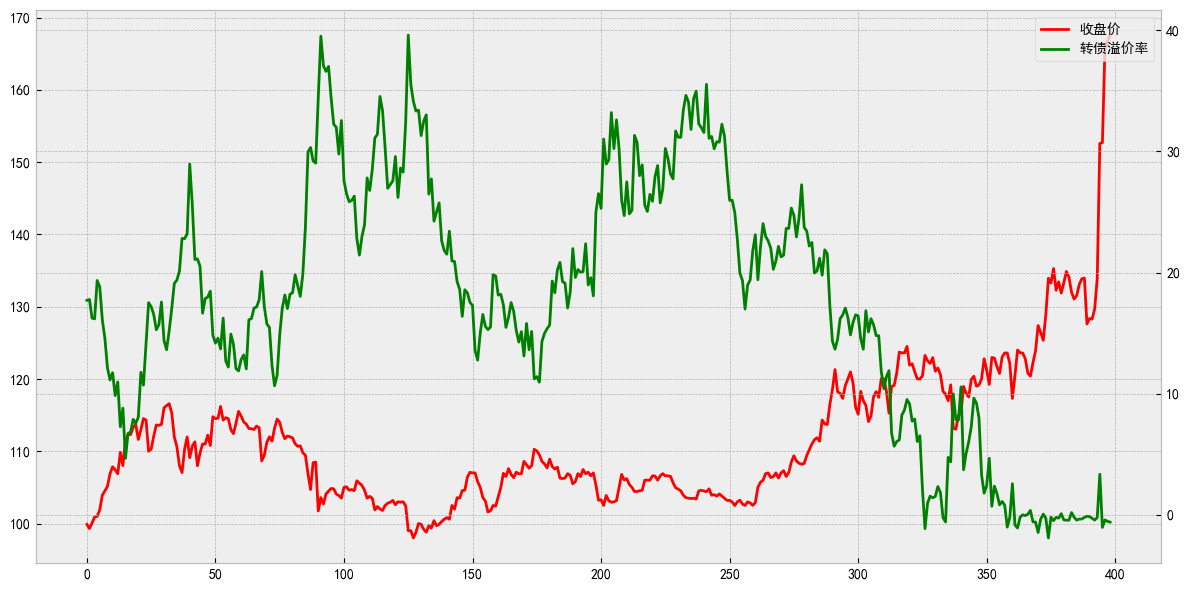

In [8]:
# ax = df.close.plot(kind='kde', title='sh110040')
# ax.figure.savefig('E:/convertible/sh110040.png')

fig, ax1 = plt.subplots()

ax1.plot(df.close, label='收盘价', color='r')

ax2 = ax1.twinx()
ax2.plot(df.zhuanguyijialv, color='g', label='转债溢价率')

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

fig.tight_layout()
plt.show()

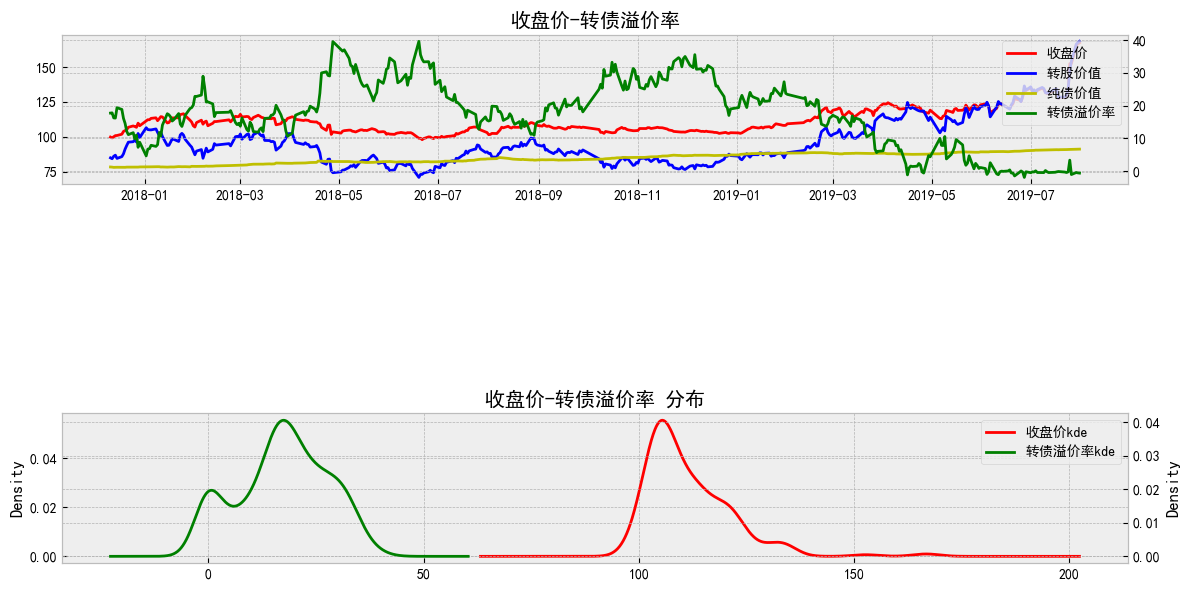

In [9]:
# figure, axis = plt.subplots(1, 2)

figure = plt.figure()
# figure.title('收盘价-转债溢价率')
# plt.title('sdfsdf')
ax1 = plt.subplot(311)
ax1.set_title('收盘价-转债溢价率')
ax1.plot(df.date, df.close, label='收盘价', color='r')
ax1.plot(df.date, df.zhuangujiazhi, label='转股价值', color='b')
ax1.plot(df.date, df.chunzhaijiazhi, label='纯债价值', color='y')

ax2 = ax1.twinx()
ax2.plot(df.date, df.zhuanguyijialv, color='g', label='转债溢价率')

# ax3 = plt.subplot(312)

ax3 = plt.subplot(313)
ax3.set_title('收盘价-转债溢价率 分布')
df.close.plot(kind='kde', color='r', ax=ax3, label='收盘价kde')
ax4 = ax3.twinx()
df.zhuanguyijialv.plot(kind='kde', color='g', ax=ax4, label='转债溢价率kde')

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

lines3, labels3 = ax3.get_legend_handles_labels()
lines4, labels4 = ax4.get_legend_handles_labels()
ax4.legend(lines3 + lines4, labels3 + labels4, loc=0)

figure.tight_layout()
plt.show()


In [29]:
# closes = []
# for f in tqdm.tqdm(os.listdir(data_root)):
#     df = pd.read_hdf(os.path.join(data_root, f))
#     closes.append(df.close)

In [30]:
# close = pd.concat(closes)

In [31]:
# close.max()

In [32]:
# close.plot(kind='kde', title='all')
# plt.show()

In [27]:
for f in tqdm.tqdm(os.listdir(data_root)):
    # plt.figure()
    try:
        code = f[:-3]
        f_dir = os.path.join('E:/convertible/fig', '%s.png' % code)
        if not os.path.exists(f_dir):
            df = pd.read_hdf(os.path.join(data_root, f))
            if df.shape[0] > 5:
                figure = plt.figure()
                
                ax1 = plt.subplot(311)
                ax1.set_title('%s 收盘价-转债溢价率' % code)
                ax1.plot(df.date, df.close, label='收盘价', color='r')
                ax1.plot(df.date, df.zhuangujiazhi, label='转股价值', color='b')
                ax1.plot(df.date, df.chunzhaijiazhi, label='纯债价值', color='y')
                
                ax2 = ax1.twinx()
                ax2.plot(df.date, df.zhuanguyijialv, color='g', label='转债溢价率')
        
                ax3 = plt.subplot(312)
                ax3.set_title('%s 收盘价-转股价值' % code)
                ax3.plot(df.date, df.close, label='收盘价', color='r')
                ax4 = ax3.twinx()
                ax4.plot(df.date, df.zhuangujiazhi, label='转股价值', color='b')
                
                
                ax5 = plt.subplot(325)
                ax5.set_title('%s 收盘价 分布' % code)
                df.close.plot(kind='kde', color='r', ax=ax5, label='收盘价kde')
                
                ax6 = plt.subplot(326)
                ax6.set_title('%s 转债溢价率 分布' % code)
                df.zhuanguyijialv.plot(kind='kde', color='g', ax=ax6, label='转债溢价率kde')
                
                lines, labels = ax1.get_legend_handles_labels()
                lines2, labels2 = ax2.get_legend_handles_labels()
                ax2.legend(lines + lines2, labels + labels2, loc=0)
        
                lines3, labels3 = ax3.get_legend_handles_labels()
                lines4, labels4 = ax4.get_legend_handles_labels()
                ax4.legend(lines3 + lines4, labels3 + labels4, loc=0)
                
                ax5.legend()
                ax6.legend()
                
                figure.tight_layout()
                figure.savefig()
                plt.close()
        else:
            pass
            # print('pass %s' % code)
    except:
        print(f)
        traceback.print_exc()

100%|██████████████████████████████████████| 811/811 [00:00<00:00, 5828.31it/s]


In [28]:
df.shape

(1, 19)

In [ ]:
sns.pairplot(df)

In [15]:
corr = df.corr()

<Axes: >

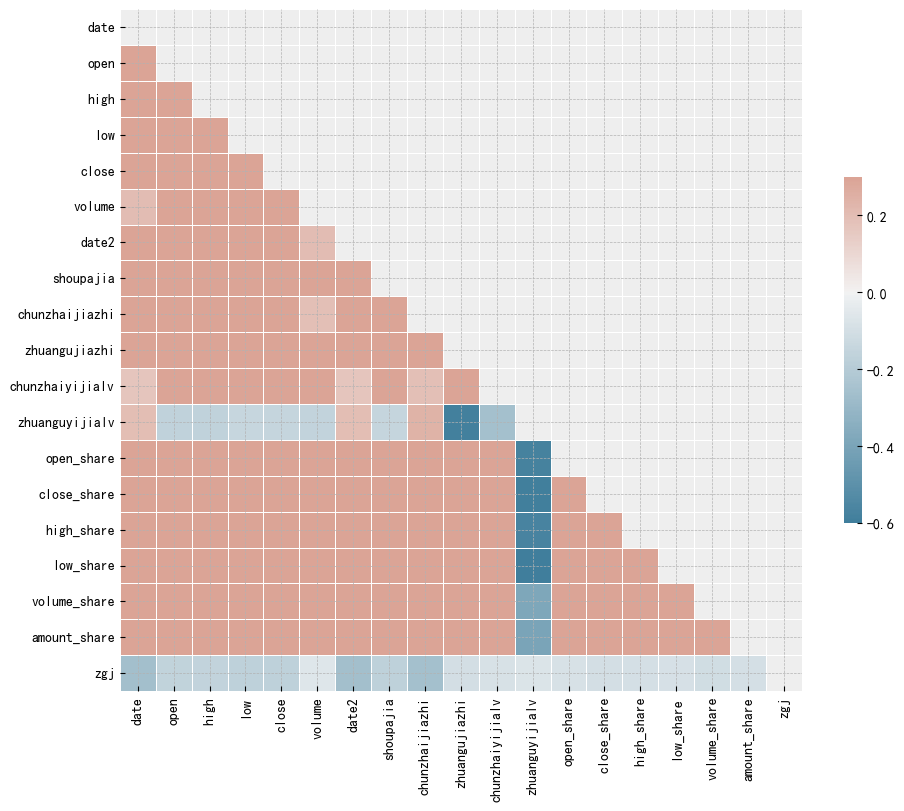

In [16]:
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .5})